In [218]:
import pandas as pd

df = pd.read_csv("./ia_tweets.csv")

df.head()

,ID,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_has_extended_profile,user_is_translator,user_protected,user_default_profile
0,0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,1,0,0,0
1,1,"@alvaropons Eso es imposible. Y sí, va a gener...",N,1,0,685,851,169490,128555,0,1,0,0,1
2,2,@alvaropons Lo disruptivo es que tras años de ...,NEU,1,0,685,851,169490,128555,0,1,0,0,1
3,3,"@alvaropons ¿""Prohibición del uso comercial de...",N,0,0,4877,538,6123,3156,0,1,0,0,0
4,4,@santoroydonoso Cómo se está estudiando prohib...,NEU,0,0,15936,2395,66945,68578,0,1,0,0,0


In [219]:
df.dtypes

ID                           int64
text                           str
polarity                       str
favorite_count               int64
retweet_count                int64
user_followers_count         int64
user_friends_count           int64
user_favourites_count        int64
user_statuses_count          int64
user_verified                int64
user_has_extended_profile    int64
user_is_translator           int64
user_protected               int64
user_default_profile         int64
dtype: object

In [220]:
from langdetect import detect, DetectorFactory

DetectorFactory.seed = 0

df['idioma'] = df['text'].apply(detect)

df = df[df["idioma"] == "es"]

df = df.drop(columns=["ID","user_has_extended_profile", "user_is_translator", "user_protected", "idioma"])

In [221]:
def filtrar_por_polaridad(field):
    return df[df["polarity"] == field]

cant_negativos = len(filtrar_por_polaridad("N"))
cant_neutros = len(filtrar_por_polaridad("NEU"))
cant_positivos =  len(filtrar_por_polaridad("P"))

print('Cantidad de tweets: ', len(df))
print('Tweets Negativos: ', cant_negativos, ', Neutros' , cant_neutros,', Positivos', cant_positivos)

# Cantidad de datos desbalanceada, se tiene mucho mas datos neutros que negativos o positivos.

Cantidad de tweets:  3660
Tweets Negativos:  551 , Neutros 2417 , Positivos 692


In [222]:
cantidad_na = df.isna().sum()
print(cantidad_na)

#(cantidad_negativos_columna("favorite_count"))

# No hay nulls o valores

text                     0
polarity                 0
favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


In [223]:
cantidad_negativos = (df.select_dtypes(include='number') < 0).sum()
print(cantidad_negativos)

favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


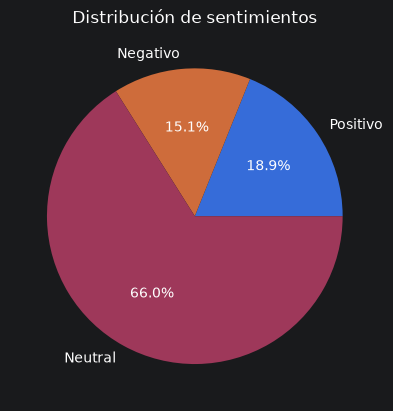

In [224]:
import matplotlib.pyplot as plt

# Datos
clases = ['Positivo', 'Negativo', 'Neutral']
cantidades = [cant_positivos, cant_negativos, cant_neutros]

# Crear gráfico
plt.pie(cantidades, labels=clases, autopct='%1.1f%%')
plt.title('Distribución de sentimientos')
plt.show()

4.1519125683060105
2243
0


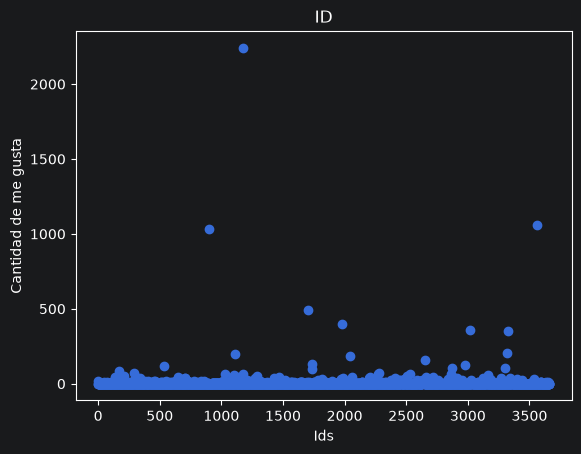

In [225]:
print(df["favorite_count"].mean())
print(df["favorite_count"].max())
print(df["favorite_count"].min())

plt.scatter(range(0,len(df)), df['favorite_count'])

plt.xlabel('Ids')
plt.ylabel('Cantidad de me gusta')
plt.title('ID')

plt.show()

0.9606557377049181
502
0


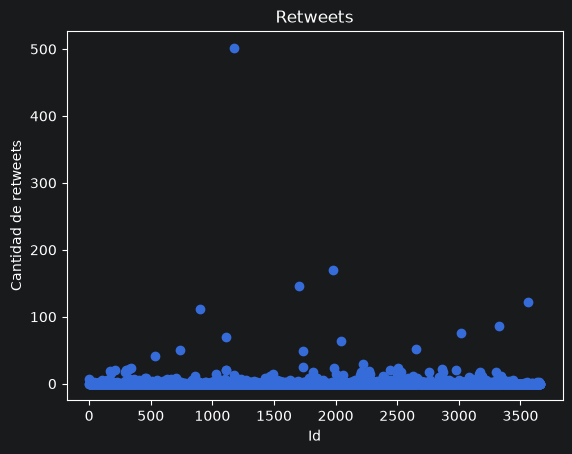

In [226]:
print(df["retweet_count"].mean())
print(df["retweet_count"].max())
print(df["retweet_count"].min())

plt.scatter(range(0,len(df)), df['retweet_count'])

plt.xlabel('Id')
plt.ylabel('Cantidad de retweets')
plt.title('Retweets')

plt.show()

Cantidad de tweets positivo con interaccion:  172
Cantidad de tweets negativos con interaccion:  139
Media de interacciones en positivos:  6.726878612716763
Media de interacciones en negativos:  3.8747731397459164


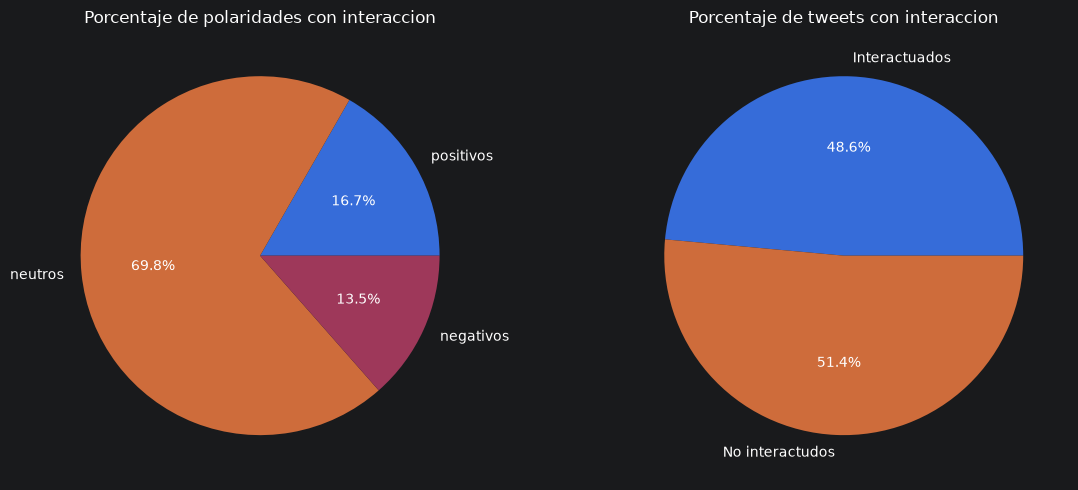

In [227]:
df['tweet_interactions'] = df['favorite_count'] + df['retweet_count']

tweets_con_interaccion = (df['tweet_interactions'] > 0).sum()
tweets_sin_interaccion = (df['tweet_interactions'] == 0).sum()

positivos_con_interaccion = (df[df['polarity'] == 'P']['tweet_interactions'] > 1).sum()
neutros_con_interaccion = (df[df['polarity'] == 'NEU']['tweet_interactions'] > 1).sum()
negativos_con_interaccion = (df[df['polarity'] == 'N']['tweet_interactions'] > 1).sum()
interaccion_positivos_media = df[df['polarity'] == 'P']['tweet_interactions'].mean()
interaccion_negativos_media = df[df['polarity'] == 'N']['tweet_interactions'].mean()

print("Cantidad de tweets positivo con interaccion: ", positivos_con_interaccion)
print("Cantidad de tweets negativos con interaccion: ", negativos_con_interaccion)
print("Media de interacciones en positivos: ", interaccion_positivos_media)
print("Media de interacciones en negativos: ", interaccion_negativos_media)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].pie([positivos_con_interaccion, neutros_con_interaccion, negativos_con_interaccion], labels=["positivos", "neutros", "negativos"], autopct='%1.1f%%')
ax[0].set_title('Porcentaje de polaridades con interaccion')

ax[1].pie([tweets_con_interaccion, tweets_sin_interaccion],
  labels=["Interactuados", "No interactudos"], autopct='%1.1f%%')
ax[1].set_title('Porcentaje de tweets con interaccion')

plt.tight_layout()
plt.show()

In [228]:
 #text
#polarity
#favorite_count
#retweet_count
#user_followers_count
#user_friends_count
#user_favourites_count         TEST (Likes que dio)
#user_statuses_count           TEST (Publicaciones y comentarios suyos)
#user_verified                 TEST
#user_default_profile          TEST (Pagina de perfil default)

import unicodedata

def contar_emojis(texto):
    return sum(1 for caracter in str(texto) if unicodedata.category(caracter) == 'So')

#df["length"] = df['text'].apply(lambda texto: len(texto.split()))
#df["hashtag_count"] = df['text'].apply(lambda texto: texto.count('#'))
#df["mention_count"] = df['text'].apply(lambda texto: texto.count('@'))
#df["url_count"] = df['text'].apply(lambda texto: texto.count('http'))
#df["punctuation_count"] = df['text'].apply(lambda texto: texto.count('?') + texto.count('!'))
#df['emoji_count'] = df['text'].apply(contar_emojis)

# :url: :mencion:

#Campos extra
#Longitud (palabras)
#Cantidad de hashtags
#Cantidad de usuarios mencionados
#Cantidad de emojis
#Cantidad de urls
#Cantidad de signos de exclamacion/interrogacion

In [229]:
df["text"] = df["text"].str.replace(r"http\S+|www\.\S+", "URL", regex=True)
df["text"] = df["text"].str.replace(r"@\w+", "MENCION", regex=True)

df.head()

,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_default_profile,tweet_interactions
0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,0,28
1,"MENCION Eso es imposible. Y sí, va a generar u...",N,1,0,685,851,169490,128555,0,1,1
2,MENCION Lo disruptivo es que tras años de deci...,NEU,1,0,685,851,169490,128555,0,1,1
3,"MENCION ¿""Prohibición del uso comercial de las...",N,0,0,4877,538,6123,3156,0,0,0
4,MENCION Cómo se está estudiando prohibir chatG...,NEU,0,0,15936,2395,66945,68578,0,0,0


In [230]:
from sklearn.model_selection import train_test_split

print(df.shape)

X = df.drop(columns=["polarity"])
y = df["polarity"]

# 60% para train y 40% para test y validacion
X_train, X_test_val, y_train, y_test_val = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Segunda división: separar test y validación
X_test, X_val, y_test, y_val = train_test_split(
    X_test_val, y_test_val,
    test_size=0.5,
    random_state=42,
    stratify=y_test_val
)

print(len(X_train)/len(df))

(3660, 11)
0.6


In [231]:
from sklearn.preprocessing import StandardScaler

#number_columns = ["favorite_count","retweet_count","user_followers_count", "user_friends_count", "user_favourites_count", "user_statuses_count", "tweet_interactions", "hashtag_count", "mention_count"]
number_columns = ["favorite_count","retweet_count","user_followers_count", "user_friends_count", "user_favourites_count", "user_statuses_count", "tweet_interactions"]

scaler = StandardScaler()

#X_train[number_columns] = scaler.fit_transform(X_train[number_columns])

#y_train = pd.get_dummies(y_train, columns=["polarity"], dtype=int, drop_first=True)

X_train.head()
y_train.head()

1468    NEU
3145    NEU
2137    NEU
3883    NEU
2562    NEU
Name: polarity, dtype: str

In [232]:
from sklearn.base import BaseEstimator, TransformerMixin
import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
import string

nltk.download('stopwords')
nltk.download('punkt_tab')
stop_words = set(stopwords.words('spanish'))

class TextCleaner(BaseEstimator, TransformerMixin):
    def __init__(self, method=None):
        self.method = method

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        # Inicializamos dentro de transform para evitar errores de multiprocessing
        stop_words = set(stopwords.words('spanish'))
        punctuation = set(string.punctuation)
        stemmer = SnowballStemmer('spanish')

        clean_X = []
        for text in X:
            # 1. Minúsculas y Tokenización
            tokens = nltk.word_tokenize(text.lower(), language='spanish')

            # 2. Remover Stopwords y Puntuación
            tokens = [t for t in tokens if t not in stop_words and t not in punctuation]

            # 3. Reducción a raíz (Stemming en español)
            if self.method == 'stem':
                tokens = [stemmer.stem(t) for t in tokens]

            clean_X.append(" ".join(tokens))
        return clean_X

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\lucas\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\lucas\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [233]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

cleaner = TextCleaner("stem")

vectores = cleaner.transform(df["text"])
vectorizer_BoW = CountVectorizer()
vectorizer_Tfidf = TfidfVectorizer()


matriz_BoW = vectorizer_BoW.fit_transform(vectores)
matriz_Tfidf = vectorizer_Tfidf.fit_transform(vectores)

print(vectorizer_BoW.get_feature_names_out())
print(matriz_BoW.toarray()[0])
#print(vectores_Tfidf.shape)

['00' '000' '003' ... '𝙀𝙣𝙩𝙧𝙚𝙥𝙖𝙧𝙦𝙪𝙚𝙨' '𝙈𝙤𝙣𝙩𝙚𝙨𝙪𝙧' '𝙈𝙤𝙣𝙩𝙞𝙚𝙡']
[0 0 0 ... 0 0 0]


In [234]:
from sentence_transformers import SentenceTransformer # <- Estandar para Embeddings

class EmbeddingTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, model_name='paraphrase-multilingual-MiniLM-L12-v2'):
        self.model_name = model_name

    def fit(self, X, y=None):
        # Cargamos el modelo aquí para evitar errores de serialización
        if not hasattr(self, "model_"):
            self.model_ = SentenceTransformer(self.model_name)
        return self

    def transform(self, X):
        # Convertimos la lista de textos en una matriz de vectores (Embeddings)
        # Esto implementa implícitamente el "Mean Pooling"
        return self.model_.encode(list(X), show_progress_bar=False)

embedding = EmbeddingTransformer()

In [235]:
embedding.fit(df["text"])
text = embedding.transform(df["text"])


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3235.74it/s]


In [236]:
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold

preprocessor = ColumnTransformer([
    (
        'text',
         Pipeline([
            ("cleaner", TextCleaner()),
            ("embedding", EmbeddingTransformer())
        ]),
         'text'),
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")), #Completa datos faltantes
            ("scaler", StandardScaler())
        ]),
        number_columns
    ),
])

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier',SVC(kernel="linear"))
])

param_grid = [
    # Opción 1: TF-IDF y CountVectorizer
    {
        "preprocessor__text__cleaner__method": [
            None, "stem"
        ],
        "preprocessor__text__embedding": [
            CountVectorizer(),
            TfidfVectorizer()
        ],
        "classifier__kernel": [
            "linear", "rbf", "poly", "sigmoid"
        ],
        "classifier__C": [0.1, 1, 10]
    },

    # Opción 2: Sentence Transformers
    {
        "preprocessor__text__cleaner__method": [
            None, "stem"
        ],
        "preprocessor__text__embedding": [
            EmbeddingTransformer()
        ],
        "classifier__kernel": [
            "linear", "rbf", "poly", "sigmoid"
        ],
        "classifier__C": [0.1, 1, 10]
    }
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(pipeline, param_grid, cv=cv, scoring='f1_macro', n_jobs=1, verbose=1, error_score="raise")
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 72 candidates, totalling 360 fits


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3639.40it/s]


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...l='linear'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'classifier__C': [0.1, 1, ...], 'classifier__kernel': ['linear', 'rbf', ...], 'preprocessor__text__cleaner__method': [None, 'stem'], 'preprocessor__text__embedding': [CountVectorizer(), TfidfVectorizer()]}, {'classifier__C': [0.1, 1, ...], 'classifier__kernel': ['linear', 'rbf', ...], 'preprocessor__text__cleaner__method': [None, 'stem'], 'preprocessor__text__embedding': [EmbeddingTransformer()]}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_`

In [237]:
# Resultados Finales
print("-" * 30)
print(f"Mejor f1_macro (CV entrenamiento): {grid_search.best_score_:.4f}")
print(f"Mejor configuración:\n{grid_search.best_params_}")
print("-" * 30)

from sklearn.metrics import classification_report, confusion_matrix, f1_score

labels = ["N", "NEU", "P"]

for nombre, X_ev, y_ev in [("Validación", X_val, y_val), ("Test", X_test, y_test)]:
    y_pred = grid_search.predict(X_ev)
    print("")
    print("===== " + nombre + " =====")
    print(f"f1_macro: {f1_score(y_ev, y_pred, average='macro'):.4f}   accuracy: {(y_pred == y_ev).mean():.4f}")
    print(classification_report(y_ev, y_pred, labels=labels, digits=3))
    print("Matriz de confusión (filas=real, columnas=predicho):")
    print(pd.DataFrame(confusion_matrix(y_ev, y_pred, labels=labels), index=labels, columns=labels))

------------------------------
Mejor f1_macro (CV entrenamiento): 0.6026
Mejor configuración:
{'classifier__C': 1, 'classifier__kernel': 'linear', 'preprocessor__text__cleaner__method': None, 'preprocessor__text__embedding': EmbeddingTransformer()}
------------------------------

===== Validación =====
f1_macro: 0.5936   accuracy: 0.7063
              precision    recall  f1-score   support

           N      0.471     0.373     0.416       110
         NEU      0.758     0.839     0.796       483
           P      0.640     0.511     0.568       139

    accuracy                          0.706       732
   macro avg      0.623     0.574     0.594       732
weighted avg      0.693     0.706     0.696       732

Matriz de confusión (filas=real, columnas=predicho):
      N  NEU   P
N    41   67   2
NEU  40  405  38
P     6   62  71

===== Test =====
f1_macro: 0.6267   accuracy: 0.7322
              precision    recall  f1-score   support

           N      0.573     0.464     0.513      

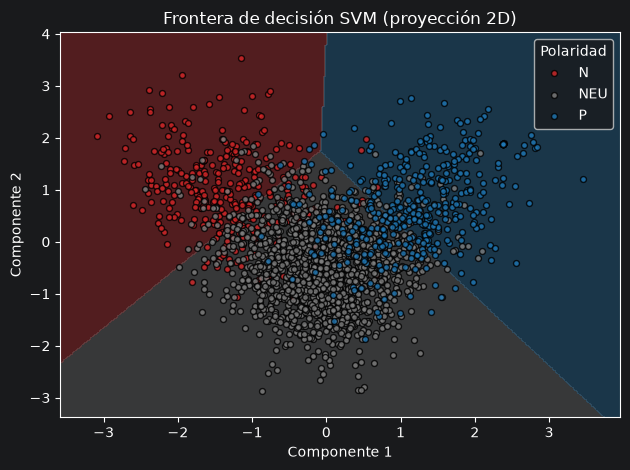

In [240]:
import numpy as np

def plot_decision_boundaries(X, y, clf, class_names=("N", "NEU", "P")):
    colors = ["#d62728", "#7f7f7f", "#1f77b4"]   # N=rojo, NEU=gris, P=azul
    h = 0.02  # Paso en la malla
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Frontera con colores discretos (sin gradiente entre clases)
    plt.contourf(xx, yy, Z, levels=np.arange(-0.5, len(class_names) + 0.5, 1),
                 colors=colors, alpha=0.3)

    # Puntos por clase, con color y leyenda correctos
    for i, nombre in enumerate(class_names):
        mask = (y == i)
        plt.scatter(X[mask, 0], X[mask, 1], c=colors[i], edgecolor="k",
                    marker="o", s=18, alpha=0.8, label=nombre)

    plt.title("Frontera de decisión SVM (proyección 2D)")
    plt.xlabel("Componente 1")
    plt.ylabel("Componente 2")
    plt.legend(title="Polaridad", loc="best")
    plt.tight_layout()
    plt.show()

# --- Grafico de frontera de decision 2D con el mejor estimador ---
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder
from scipy import sparse

best_pipeline = grid_search.best_estimator_

# 1) Features transformadas por el mejor preprocesador
X_transformed = best_pipeline.named_steps["preprocessor"].transform(X_train)

# 2) Etiquetas a enteros (LabelEncoder ordena alfabeticamente: 0=N, 1=NEU, 2=P)
y_encoded = LabelEncoder().fit_transform(y_train)

# 3) Reduccion a 2D con LDA (supervisado). PCA/SVD de TF-IDF explica muy poca
#    varianza y la SVM termina prediciendo siempre la clase mayoritaria (NEU).
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.preprocessing import StandardScaler

X_dense = X_transformed.toarray() if sparse.issparse(X_transformed) else np.asarray(X_transformed)
X_2d = LDA(n_components=2).fit_transform(X_dense, y_encoded)
X_2d = StandardScaler().fit_transform(X_2d)

# 4) SVM con los mejores hiperparametros, entrenado en 2D
best_svm = best_pipeline.named_steps["classifier"]
svm_2d = SVC(kernel=best_svm.kernel, C=best_svm.C, gamma=best_svm.gamma,
             degree=best_svm.degree, coef0=best_svm.coef0)
svm_2d.fit(X_2d, y_encoded)

# 5) Graficar la frontera de decision
plot_decision_boundaries(X_2d, y_encoded, svm_2d)
